# Comparing: 2 groups vs 3 groups
**Q3: Which provinces are alike, and where does Alberta sit?**

Here we compares the K-Means result with **2 groups** (used in the project) and **3 groups** (suggested by the elbow).

The data comes from the cleaned/model_data.csv` and the star schema tables, created from the `Data_Preparation.ipynb`.

In [1]:
# Loading the needed tools.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

# Hide warning messages.
import warnings
warnings.filterwarnings("ignore")

In [2]:
# loading the files.
cleaned_path='../cleaned/'

# Building the province profiles

In [3]:
# Open the model dataset (10 provinces, 2016 to 2025) and the star schema tables.
# The star schema tables are needed for Canada's own values, which are not in model_data.
data=pd.read_csv(cleaned_path+'model_data.csv')
fact=pd.read_csv(cleaned_path+'Fact_WaitTimes.csv')
geo=pd.read_csv(cleaned_path+'Dim_Geography.csv')
proc=pd.read_csv(cleaned_path+'Dim_Procedure.csv')

In [4]:
# Build one profile row per province: its 2016 to 2025 averages for the SIX features
#   1 to 4: share treated on time for hip, knee, cataract and radiation therapy
#   5: share of the population aged 65+
#   6: median age
# Hip fracture repair is left out because Quebec does not report it.
# one row per province, one column per procedure.
q3_proc=['Hip Replacement','Knee Replacement','Cataract Surgery','Radiation Therapy']
q3=data[data['Indicator'].isin(q3_proc)]

profile=pd.crosstab(q3['Province'],q3['Indicator'],values=q3['Pct_Within_Benchmark'],aggfunc='mean')
profile['Pct_65plus']=data.groupby('Province')['Pct_65plus'].mean()
profile['Median_Age']=data.groupby('Province')['Median_Age'].mean()

In [5]:
# Canada's profile, built the same way, so it can be placed among the groups afterwards.
# NB: Canada is the benchmark, not a comparison case.
full=pd.merge(fact,geo,on='GeoKey')
full=pd.merge(full,proc,on='ProcedureKey')

ca=full[(full['Province']=='Canada') & (full['Indicator'].isin(q3_proc))]
canada_profile=pd.crosstab(ca['Province'],ca['Indicator'],values=ca['Pct_Within_Benchmark'],aggfunc='mean')
canada_profile['Pct_65plus']=full[full['Province']=='Canada']['Pct_65plus'].mean()
canada_profile['Median_Age']=full[full['Province']=='Canada']['Median_Age'].mean()

In [6]:
# Standardize the six features: (value - average) / standard deviation.
# K-Means measures distance, so every feature must be on the same scale.
# Canada is scaled with the provinces' average and spread, so it sits on the same map.
p_mean=profile.mean()
p_std=profile.std()
profile_s=(profile-p_mean)/p_std
canada_s=(canada_profile-p_mean)/p_std

# Elbow and silhouette for 2 to 6 groups

In [7]:
# Try 2 to 6 groups and record two scores for each:
# Elbow method: how spread out the provinces are inside their groups. 
# Silhouette: from -1 to 1, showshow clearly each province sits in its own group rather than the
#   nearest other group (higher = clearer groups).
k_range=list(range(2,7))
inertias=[]
silhouettes=[]

for k in k_range:
    km=KMeans(n_clusters=k,random_state=123,n_init=10)
    labels=km.fit_predict(profile_s)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(profile_s,labels))

print("Inertia:   ",[round(i,1) for i in inertias])
print("Silhouette:",[round(x,3) for x in silhouettes])

Inertia:    [33.9, 21.3, 14.9, 9.6, 6.8]
Silhouette: [0.273, 0.269, 0.265, 0.224, 0.185]


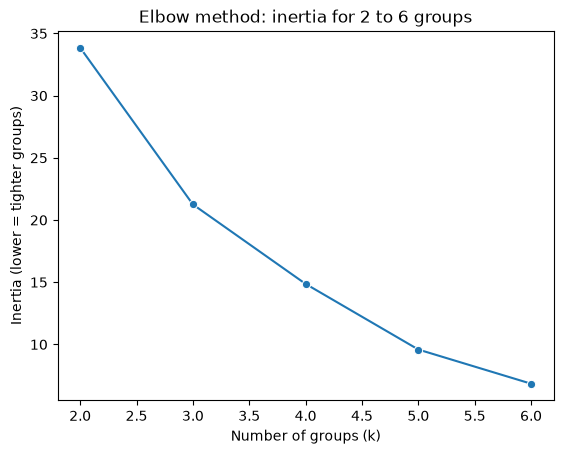

In [8]:
# Elbow chart
sns.lineplot(x=k_range,y=inertias,marker='o')
plt.title('Elbow method: inertia for 2 to 6 groups')
plt.xlabel('Number of groups (k)')
plt.ylabel('Inertia (lower = tighter groups)')
plt.show()

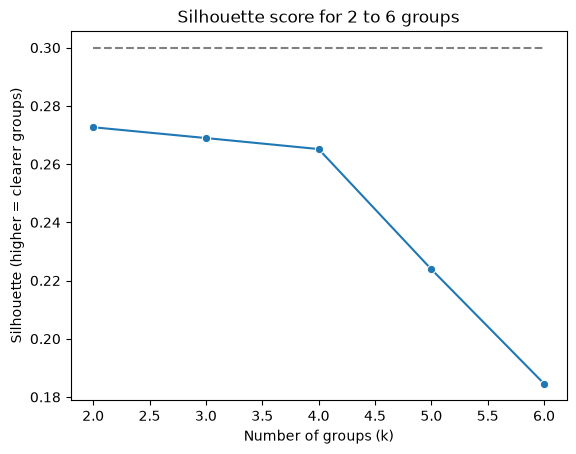

In [9]:
# Silhouette chart
sns.lineplot(x=k_range,y=silhouettes,marker='o')
sns.lineplot(x=k_range,y=[0.30]*len(k_range),linestyle='--',color='grey')
plt.title('Silhouette score for 2 to 6 groups')
plt.xlabel('Number of groups (k)')
plt.ylabel('Silhouette (higher = clearer groups)')
plt.show()

In [10]:
# Building the K-Means model with 2 groups and with 3 groups
kmeans2=KMeans(n_clusters=2,random_state=123,n_init=10)
kmeans3=KMeans(n_clusters=3,random_state=123,n_init=10)
profile['Group_k2']=kmeans2.fit_predict(profile_s)
profile['Group_k3']=kmeans3.fit_predict(profile_s)

In [11]:
# Fit of each province: its own silhouette value with 2 groups and with 3 groups.
# The project's silhouette score (0.273 and 0.269) is the average of these values.
fit=pd.DataFrame({'Fit_k2':silhouette_samples(profile_s,profile['Group_k2']),
                  'Fit_k3':silhouette_samples(profile_s,profile['Group_k3'])},index=profile.index)
print("Average:",fit.mean().round(3).to_dict())
fit.round(2)

Average: {'Fit_k2': 0.273, 'Fit_k3': 0.269}


,Fit_k2,Fit_k3
Province,,
Alberta,0.29,0.11
British Columbia,0.32,0.29
Manitoba,0.48,0.46
New Brunswick,0.19,0.35
Newfoundland and Labrador,0.39,0.50
Nova Scotia,0.36,0.51
Ontario,0.05,0.00
Prince Edward Island,0.18,0.10
Quebec,0.22,0.13


# Scatter plots

In [12]:
# A scatter plot; (x): average share treated on time for the 3 planned procedures (hip, knee, cataract)
# (y):share of the population aged 65+
planned=['Hip Replacement','Knee Replacement','Cataract Surgery']
profile['Planned_OnTime']=profile[planned].mean(axis=1)
canada_x=canada_profile[planned].mean(axis=1).iloc[0]
canada_y=canada_profile['Pct_65plus'].iloc[0]

# Short province codes for the labels.
codes={'Newfoundland and Labrador':'NL','Prince Edward Island':'PE','Nova Scotia':'NS',
       'New Brunswick':'NB','Quebec':'QC','Ontario':'ON','Manitoba':'MB',
       'Saskatchewan':'SK','Alberta':'AB','British Columbia':'BC'}

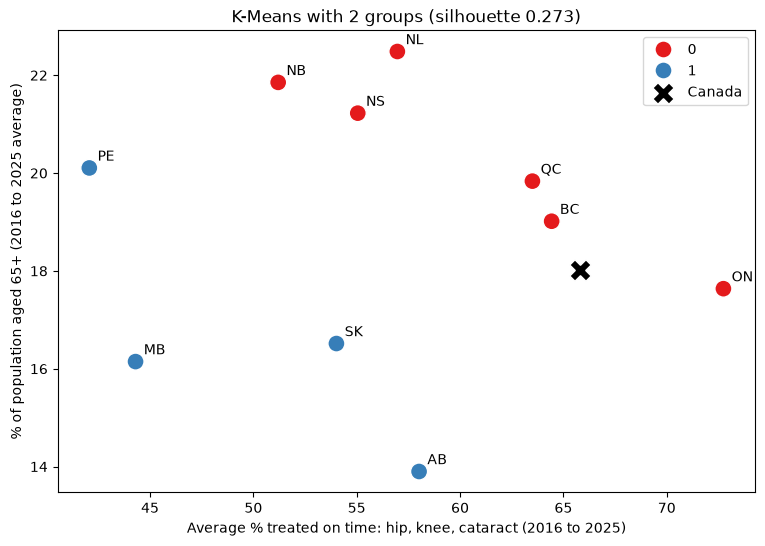

In [13]:
# Scatter plot for 2 groups. Colours = groups; the X = Canada's profile.
# plt.text writes each province's code next to its point.
plt.figure(figsize=(9,6))
sns.scatterplot(x='Planned_OnTime',y='Pct_65plus',hue='Group_k2',data=profile,s=150,palette='Set1')
sns.scatterplot(x=[canada_x],y=[canada_y],marker='X',s=250,color='black',label='Canada')
for name in profile.index:
    plt.text(profile.loc[name,'Planned_OnTime']+0.4,profile.loc[name,'Pct_65plus']+0.15,codes[name])
plt.title('K-Means with 2 groups (silhouette 0.273)')
plt.xlabel('Average % treated on time: hip, knee, cataract (2016 to 2025)')
plt.ylabel('% of population aged 65+ (2016 to 2025 average)')
plt.show()

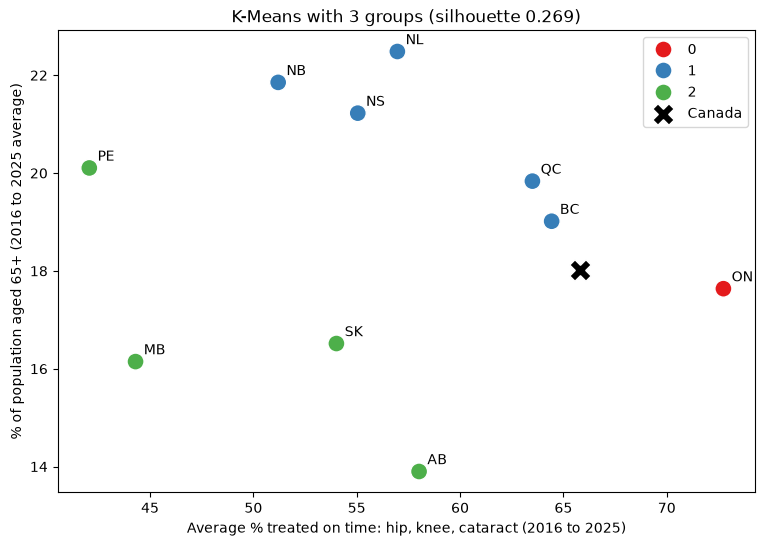

In [14]:
# Scatter plot for 3 groups, same labels as 2 groups.
plt.figure(figsize=(9,6))
sns.scatterplot(x='Planned_OnTime',y='Pct_65plus',hue='Group_k3',data=profile,s=150,palette='Set1')
sns.scatterplot(x=[canada_x],y=[canada_y],marker='X',s=250,color='black',label='Canada')
for name in profile.index:
    plt.text(profile.loc[name,'Planned_OnTime']+0.4,profile.loc[name,'Pct_65plus']+0.15,codes[name])
plt.title('K-Means with 3 groups (silhouette 0.269)')
plt.xlabel('Average % treated on time: hip, knee, cataract (2016 to 2025)')
plt.ylabel('% of population aged 65+ (2016 to 2025 average)')
plt.show()